# Hazard Index (0–10): results

This notebook reads saved results only (`artifacts/`); it never trains or downloads. Regenerate the inputs with
`build_dataset.py`, `compute_severity.py`, `train.py`, `evaluate.py` and `dryrun.py` (run order in `../README.md`).
Launch it from `models/hazard-index/notebooks/` (or `models/hazard-index/`).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
ROOT = next(p for p in (cwd, cwd.parent, cwd / "models" / "hazard-index") if (p / "hazidx").is_dir())
sys.path.insert(0, str(ROOT))
from hazidx import config, plots, tiermap  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
%matplotlib inline
plots.style()
pd.set_option("display.precision", 3)

ART = ROOT / "artifacts"
version = json.loads((ART / "models" / "latest.json").read_text())["model_version"]
MD = ART / "models" / version
meta = json.loads((MD / "metadata.json").read_text())
metrics = json.loads((MD / "metrics.json").read_text())
labels = json.loads((ART / "labels_report.json").read_text())
sev = json.loads((ART / "severity.json").read_text())
preds = pd.read_parquet(MD / "predictions.parquet")
print(version)
print("years:", {k: v for k, v in meta["years"].items() if isinstance(v, list)})
print("calibration:", meta["years"]["calibration"], "| settings grid:", meta["grid"])

hazidx-0.1.0+2018-2022.23ed6848
years: {'train': [2018, 2019, 2020, 2021, 2022], 'model_selection': [2023], 'test': [2024, 2025]}
calibration: Platt, out-of-fold, GroupKFold by year, 5 folds | settings grid: V1


## 1. Data coverage and labels

In [2]:
cov = pd.DataFrame({"plants with weather": pd.Series(labels["plants_per_year"])})
by_year = pd.DataFrame(labels["share_by_year"])
display(cov.join(by_year.add_prefix("event share ")).rename_axis("year"))
est = pd.DataFrame({"measured share of plant-days": pd.Series(labels["share_of_days"]),
                    "plan estimate (low)": {f: v[0] for f, v in labels["plan_estimate"].items()},
                    "plan estimate (high)": {f: v[1] for f, v in labels["plan_estimate"].items()}})
display(est.style.format("{:.2%}"))
print("every family has events in every year:", labels["every_family_every_year"], labels["missing_family_years"])
display(pd.DataFrame(labels["matches_by_method"]).fillna(0).astype(int).rename_axis("match method"))

,plants with weather,event share heat,event share storm,event share flood,event share fire
year,,,,,
2018,59,0.004,0.012,0.016,0.003
2019,60,0.006,0.015,0.024,0.002
2020,60,0.006,0.014,0.011,0.005
2021,60,0.006,0.012,0.011,0.003
2022,60,0.009,0.013,0.012,0.003
2023,60,0.022,0.015,0.009,0.003
2024,60,0.008,0.013,0.013,0.003
2025,60,0.007,0.014,0.009,0.006


,measured share of plant-days,plan estimate (low),plan estimate (high)
heat,0.85%,0.50%,2.00%
storm,1.35%,1.00%,1.50%
flood,1.32%,0.50%,1.00%
fire,0.34%,0.10%,0.30%


every family has events in every year: True []


,fire,flood,heat,storm
match method,,,,
zone_name,117,0,153,0
zone_code,31,0,607,0
radius,0,3073,0,7677


Plants with the most labelled days per family. Long multi-day records (river floods, wildfires) and the zone-name rule
in very large western counties produce the outliers; the model has no plant identifiers, so it cannot learn them.

In [3]:
bp = pd.DataFrame(labels["share_by_plant"]).T
display(pd.concat({f: bp.sort_values(f, ascending=False).head(5)[["name", f]].reset_index(names="eia")
                   for f in config.FAMILIES}, axis=1))

heat                             storm                       flood  \
     eia                 name   heat   eia          name  storm    eia   
0   6146          Martin Lake  0.065  3166  Peach Bottom  0.034   6113   
1  55380  Union Power Station  0.064    46  Browns Ferry  0.033  55380   
2   6145        Comanche Peak  0.053  3935   John E Amos  0.028   8102   
3   6008           Palo Verde  0.051  2500    Ravenswood  0.028   6166   
4   8223        Springerville  0.048   703         Bowen  0.027   1403   

                               fire                        
                  name  flood   eia           name   fire  
0               Gibson  0.121  6163   Grand Coulee  0.104  
1  Union Power Station   0.11   400         Haynes  0.037  
2     Gavin Power, LLC  0.042   621   Turkey Point  0.014  
3             Rockport  0.039  6099  Diablo Canyon  0.014  
4      Nine Mile Point   0.03  6145  Comanche Peak  0.008

## 2. Severity weights (OSHA Severe Injury Reports)

In [4]:
s = pd.DataFrame(sev["families"]).T
s["rate 90% interval"] = s["rate_90"].map(lambda v: f"[{v[0]:.6f}, {v[1]:.6f}]")
display(s[["injuries_N", "event_days_D", "shrunk_rate_r", "rate 90% interval", "weight_s"]])
print(f"{len(sev['population']['federal_osha_states'])} federal-OSHA states; NAICS {sev['population']['naics_prefixes']};",
      f"prior {sev['prior_injuries']} injuries; r0 = {sev['r0']:.6f}")
print(sev["note"])

,injuries_N,event_days_D,shrunk_rate_r,rate 90% interval,weight_s
heat,233,46842,0.005,"[0.004191, 0.005188]",1.0
storm,27,97292,0.0,"[0.000230, 0.000413]",0.834
flood,0,57956,0.0,"[0.000032, 0.000148]",0.75
fire,1,8543,0.0,"[0.000208, 0.000836]",0.859


34 federal-OSHA states; NAICS ['2211', '237']; prior 5.0 injuries; r0 = 0.001239
Storm, flood and fire weights rest on very few injuries (fire usually on none), so they mostly reflect the prior. D mixes county-days (storm, flash flood) and zone-days (heat, wildfire), which inflates the heat rate; the log scale limits any family's reduction to 25%.


In [5]:
m = pd.read_csv(ART / "severity_matches.csv")
display(m[m["family"] != "heat"][["EventDate", "State", "family", "matched", "EventTitle"]])

,EventDate,State,family,matched,EventTitle
0,2/18/2015,ILLINOIS,storm,gust of wind,Struck by or caught in swinging door or gate
8,7/16/2015,ILLINOIS,storm,storm,"Direct exposure to electricity, greater than 2..."
49,7/7/2017,MISSISSIPPI,storm,thunderstorm,"Indirect exposure to electricity, greater than..."
61,8/17/2017,KANSAS,storm,storm,Struck by object or equipment rolling freely
93,5/21/2019,TEXAS,storm,tornado,"Struck by dislodged flying object, particle"
94,6/16/2019,OHIO,storm,storms,"Struck by swinging or slipping object, other t..."
96,6/29/2019,TEXAS,storm,lightning,"Direct exposure to electricity, greater than 2..."
112,8/15/2019,ALABAMA,storm,lightning,"Direct exposure to electricity, greater than 2..."
113,8/15/2019,COLORADO,storm,storm,"Direct exposure to electricity, unspecified"
119,9/11/2019,TEXAS,storm,lightning,"Indirect exposure to electricity, greater than..."


## 3. Test metrics (2024–2025)

In [6]:
rows = {}
for f, v in metrics["families"].items():
    rows[f] = {"events": v["events"], "PR-AUC full": v["pr_auc"]["full"], "PR-AUC past-only": v["pr_auc"]["past_only"],
               "PR-AUC climatology": v["pr_auc"]["climatology"], "PR-AUC rule": v["pr_auc"]["rule"],
               "ROC-AUC full": v["roc_auc"]["full"], "ROC-AUC past-only": v["roc_auc"]["past_only"],
               "BSS full": v["brier_skill"]["full"], "BSS past-only": v["brier_skill"]["past_only"],
               "forecast-dependent share": v["forecast_dependent_share"],
               "beats climatology (criterion 3)": v["beats_climatology"]}
display(pd.DataFrame(rows).T)
rng = pd.DataFrame({f: {k: (None if r is None else f"[{r[0]:.3f}, {r[1]:.3f}]") for k, r in v.get("ranges_90", {}).items()}
                    for f, v in metrics["families"].items()}).T
print("90% ranges from resampling plants (200 resamples):")
display(rng)

,events,PR-AUC full,PR-AUC past-only,PR-AUC climatology,PR-AUC rule,ROC-AUC full,ROC-AUC past-only,BSS full,BSS past-only,forecast-dependent share,beats climatology (criterion 3)
heat,327,0.291,0.102,0.175,0.15,0.957,0.911,0.104,-0.04,1.639,True
storm,599,0.145,0.024,0.038,0.027,0.908,0.702,0.065,-0.006,1.126,True
flood,488,0.088,0.069,0.058,0.052,0.858,0.834,0.03,0.019,0.62,True
fire,196,0.063,0.048,0.177,None,0.863,0.862,-0.093,-0.097,None,False


90% ranges from resampling plants (200 resamples):


,roc_auc_full,pr_auc_full,pr_auc_climatology,brier_skill_full
heat,"[0.906, 0.985]","[0.158, 0.511]","[0.088, 0.251]","[-0.036, 0.216]"
storm,"[0.898, 0.918]","[0.126, 0.166]","[0.032, 0.041]","[0.055, 0.074]"
flood,"[0.836, 0.882]","[0.058, 0.128]","[0.021, 0.123]","[-0.003, 0.075]"
fire,"[0.623, 0.956]","[0.002, 0.177]","[0.010, 0.315]","[-0.178, -0.000]"


PR-AUC is the area under the precision-recall curve (more informative than ROC-AUC for rare events); BSS is the Brier
skill score against plant-month climatology (above 0 is better than climatology). The forecast-dependent share is the
part of the skill above climatology that needs same-day (forecast) inputs.

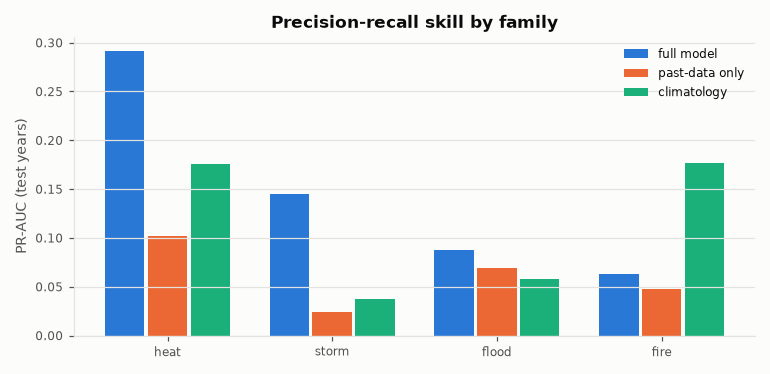

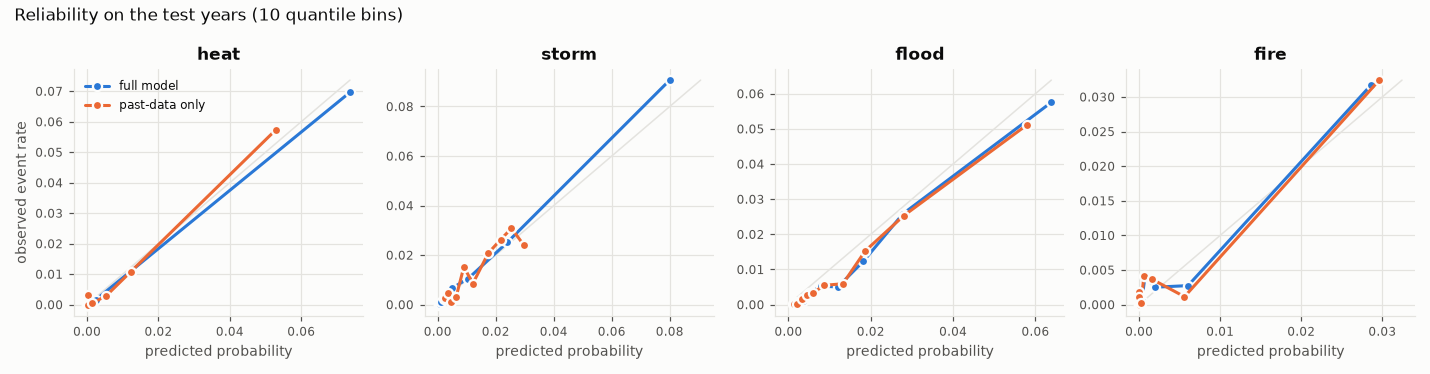

In [7]:
display(Image(filename=str(MD / "figures" / "pr_auc.png")))
display(Image(filename=str(MD / "figures" / "reliability.png")))

## 4. The 0–10 map

fallback points used: False


,R,score
0,0.000,0.0
1,0.017,1.5
2,0.017,2.0
3,0.039,4.0
4,0.073,7.0
5,0.142,7.5
6,0.390,10.0


removed (median R not increasing): [{'median_r': 0.01720050253402996, 'rule_max': 2.5, 'days': 1815}, {'median_r': 0.01270447512035612, 'rule_max': 3.0, 'days': 22956}, {'median_r': 0.030825620910877302, 'rule_max': 5.0, 'days': 6668}, {'median_r': 0.03305937227563007, 'rule_max': 6.0, 'days': 4973}, {'median_r': 0.09817849492017142, 'rule_max': 9.0, 'days': 135}]


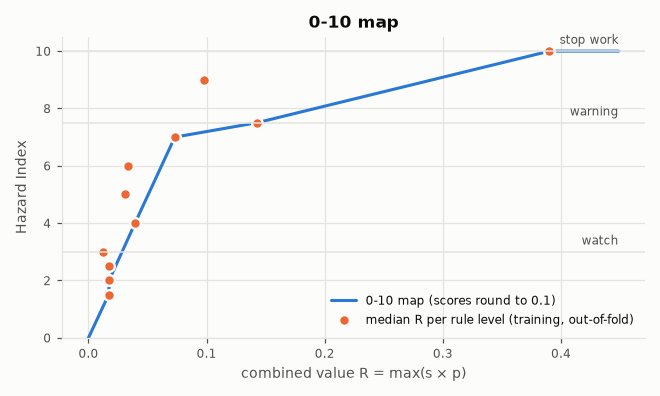

In [8]:
tm = json.loads((MD / "tier_map.json").read_text())
print("fallback points used:" , tm["fallback"])
display(pd.DataFrame(tm["points"], columns=["R", "score"]))
if tm["removed"]:
    print("removed (median R not increasing):", tm["removed"])
display(Image(filename=str(MD / "figures" / "tier_map.png")))

**Rejected alternative: quantile matching.** It maps `R` so that ML scores have the same distribution as the
historical rule maximum. Below, both maps are fitted on the same out-of-fold training days and applied to the test
years. Quantile matching can never show more total danger than the rules, and it inherits the steps of the rule scores.

,fitted map,quantile matching,rule maximum
>= 3,22.88%,36.33%,33.96%
>= 7.5,2.57%,1.60%,2.01%
>= 10,0.33%,0.10%,0.23%


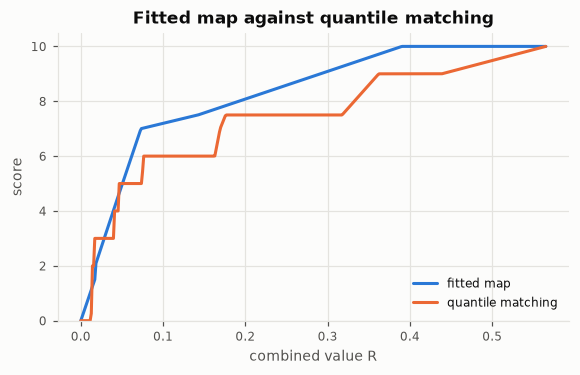

In [9]:
oof = preds[preds["split"] == "train_oof"]
test = preds[preds["split"] == "test"].copy()
q = np.linspace(0, 1, 1001)
r_q, rule_q = np.quantile(oof["R"], q), np.quantile(oof["rule_max"], q)
test["score_quantile_matched"] = np.interp(test["R"], r_q, rule_q)
share = lambda s, c: float((s >= c).mean())
cmp = pd.DataFrame({name: {f">= {c}": share(test[col], c) for c in (3, 7.5, 10)}
                    for name, col in (("fitted map", "score"), ("quantile matching", "score_quantile_matched"),
                                      ("rule maximum", "rule_max"))})
display(cmp.style.format("{:.2%}"))
grid = np.linspace(0, max(oof["R"].quantile(0.999), tm["points"][-1][0]), 400)
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(grid, np.interp(grid, [p[0] for p in tm["points"]], [p[1] for p in tm["points"]]), color=plots.SERIES[0], label="fitted map")
ax.plot(grid, np.interp(grid, r_q, rule_q), color=plots.SERIES[1], label="quantile matching")
ax.set_xlabel("combined value R"); ax.set_ylabel("score"); ax.set_ylim(0, 10.5); ax.legend(loc="lower right")
ax.set_title("Fitted map against quantile matching")
plt.show()

## 5. Index tier against rule tier, and escalation (test years)

In [10]:
ix = metrics["index"]
print(f"ROC-AUC for any event: index {ix['roc_auc_any_event']:.3f}, rule maximum {ix['rule_max_roc_auc_any_event']:.3f}")
print(f"PR-AUC for any event:  index {ix['pr_auc_any_event']:.3f}, rule maximum {ix['rule_max_pr_auc_any_event']:.3f}"
      f"  (event rate {ix['any_event_rate']:.3f})")
order = ["none", "watch", "warning", "stop"]
days = pd.DataFrame(ix["tier_table"]["days"]).T.loc[order, order]
rate = pd.DataFrame(ix["tier_table"]["event_rate"]).T.loc[order, order]
days.index.name, days.columns.name = "index tier", "rule tier"
display(days)
display(rate.style.format("{:.1%}", na_rep="-"))
e = ix["escalation"]
print(f"Escalation (index > rule max + {e['points']:g}): {e['days']} days, event rate "
      f"{e['event_rate'] if e['event_rate'] is None else round(e['event_rate'], 3)} vs "
      f"{e['same_rule_tier_event_rate'] if e['same_rule_tier_event_rate'] is None else round(e['same_rule_tier_event_rate'], 3)}"
      " on other days at the same rule tier")
print("top driver share:", {k: round(v, 3) for k, v in ix["top_driver_share"].items()})

ROC-AUC for any event: index 0.830, rule maximum 0.733
PR-AUC for any event:  index 0.200, rule maximum 0.109  (event rate 0.035)


rule tier,none,watch,warning,stop
index tier,,,,
none,25052,8661,64,0
watch,3720,4778,378,21
warning,153,533,258,39
stop,1,22,79,41


,none,watch,warning,stop
none,0.9%,2.4%,4.7%,-
watch,6.4%,10.4%,10.6%,4.8%
warning,9.8%,30.0%,29.5%,46.2%
stop,0.0%,27.3%,51.9%,46.3%


Escalation (index > rule max + 2): 7862 days, event rate 0.087 vs 0.017 on other days at the same rule tier
top driver share: {'flood': 0.565, 'storm': 0.206, 'fire': 0.17, 'heat': 0.059}


## 6. Case study: West County Energy Center, August 2024 (the brief's scenario)

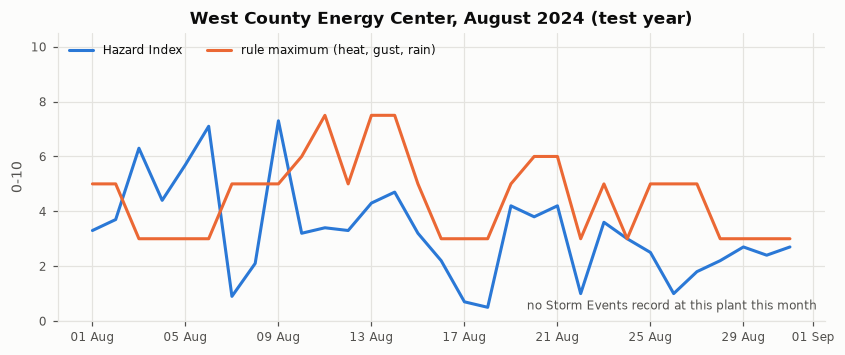

,date,score,top_driver,p_heat,p_storm,p_flood,p_fire,rule_max,wbgt_max,hi_max,gust_max,rain_24h,rain_prev7d,sm07_mean,y_heat,y_storm,y_flood
66674,2024-08-09,7.3,storm,1.785e-03,0.133,0.042,5.793e-06,5.0,86.06,99.68,21.3,19.3,49.4,0.33,0,0,0
66671,2024-08-06,7.1,storm,1.659e-03,0.106,0.022,5.793e-06,3.0,84.83,99.62,27.3,6.2,70.2,0.35,0,0,0
66668,2024-08-03,6.3,storm,6.859e-04,0.078,0.029,5.793e-06,3.0,83.90,95.84,28.4,11.4,57.5,0.36,0,0,0
66670,2024-08-05,5.7,storm,9.013e-04,0.071,0.038,5.793e-06,3.0,83.78,97.54,33.1,10.8,78.4,0.36,0,0,0
66679,2024-08-14,4.7,heat,4.747e-02,0.035,0.013,5.793e-06,7.5,89.55,107.88,13.0,3.6,37.0,0.33,0,0,0
66669,2024-08-04,4.4,storm,6.059e-04,0.053,0.041,5.793e-06,3.0,81.54,92.27,32.4,15.8,68.8,0.37,0,0,0
66678,2024-08-13,4.3,heat,4.226e-02,0.041,0.014,5.793e-06,7.5,88.91,106.52,12.1,2.1,41.1,0.34,0,0,0
66684,2024-08-19,4.2,storm,2.325e-03,0.050,0.022,5.793e-06,5.0,86.40,99.13,13.9,7.8,27.3,0.32,0,0,0


In [11]:
wc = preds[(preds["eia_plant_id"] == "56407") & (preds["date"].dt.strftime("%Y-%m") == "2024-08")].copy()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(wc["date"], wc["score"], color=plots.SERIES[0], label="Hazard Index")
ax.plot(wc["date"], wc["rule_max"], color=plots.SERIES[1], label="rule maximum (heat, gust, rain)")
ev = wc[wc["y_any"] == 1]
if len(ev):
    ax.plot(ev["date"], np.full(len(ev), 0.4), linestyle="none", marker="v", markersize=7, color=plots.SERIES[2],
            markeredgecolor=plots.SURFACE, markeredgewidth=1.5, label="Storm Events day (any family)")
else:
    ax.text(0.99, 0.04, "no Storm Events record at this plant this month", transform=ax.transAxes, ha="right",
            fontsize=8, color=plots.TEXT_2)
import matplotlib.dates as mdates
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_ylim(0, 10.5); ax.set_ylabel("0-10"); ax.legend(loc="upper left", ncols=3)
ax.set_title("West County Energy Center, August 2024 (test year)")
plt.show()
cols = ["date", "score", "top_driver", "p_heat", "p_storm", "p_flood", "p_fire", "rule_max", "wbgt_max", "hi_max",
        "gust_max", "rain_24h", "rain_prev7d", "sm07_mean", "y_heat", "y_storm", "y_flood"]
display(wc.sort_values("score", ascending=False)[cols].head(8))

In [12]:
replays = sorted((ART / "dryrun").glob("replay_*_56407.csv"))
for f in replays:
    print(f.name)
    display(pd.read_csv(f, dtype={"eia_plant_id": str}).T)

replay_20240809_56407.csv


,0,1
eia_plant_id,56407,56407
horizon,now,tomorrow
score,7.3,3.2
model_version,hazidx-0.1.0+2018-2022.23ed6848,hazidx-0.1.0+2018-2022.23ed6848
site_name,West County Energy Center,West County Energy Center
timezone,America/New_York,America/New_York
local_date,2024-08-09,2024-08-10
top_driver,storm,storm
r_raw,0.111,0.031
p_heat,0.002,0.011


replay_20240814_56407.csv


,0,1
eia_plant_id,56407,56407
horizon,now,tomorrow
score,4.7,3.2
model_version,hazidx-0.1.0+2018-2022.23ed6848,hazidx-0.1.0+2018-2022.23ed6848
site_name,West County Energy Center,West County Energy Center
timezone,America/New_York,America/New_York
local_date,2024-08-14,2024-08-15
top_driver,heat,storm
r_raw,0.048,0.031
p_heat,0.048,0.004


## 7. Live dry-run

In [13]:
runs = sorted((ART / "dryrun").glob("ml_scores_*.csv"))
live = pd.read_csv(runs[-1], dtype={"eia_plant_id": str})
print(runs[-1].name, len(live), "rows;", live["model_version"].iloc[0])
display(live.groupby("horizon")["score"].describe())
display(pd.crosstab(live["top_driver"], live["horizon"]))
print("rows with drift flags:", int(live["drift_flags"].notna().sum()), "| soil source:", live["soil_source"].value_counts().to_dict())
display(live.sort_values("risk_preview", ascending=False)[["site_name", "horizon", "local_date", "score", "top_driver",
        "rule_max_fc", "risk_preview", "forecast_hours", "drift_flags"]].head(10))

ml_scores_20261018T001527Z.csv 120 rows; hazidx-0.1.0+2018-2022.23ed6848


,count,mean,std,min,25%,50%,75%,max
horizon,,,,,,,,
now,60.0,1.057,1.501,0.1,0.2,0.4,0.850,7.2
tomorrow,60.0,0.768,1.099,0.1,0.1,0.3,0.725,4.7


horizon,now,tomorrow
top_driver,,
fire,24,23
flood,24,33
storm,12,4


rows with drift flags: 13 | soil source: {'ecmwf_ifs': 120}


,site_name,horizon,local_date,score,top_driver,rule_max_fc,risk_preview,forecast_hours,drift_flags
94,Calvert Cliffs Nuclear Power Plant,now,2026-10-17,7.2,storm,4.0,7.2,3,rain_hr_max>p99.5;wind_max>p99.5
84,Victor J Daniel Jr,now,2026-10-17,0.1,flood,6.0,6.0,4,NaN
48,Roxboro,now,2026-10-17,5.7,storm,3.0,5.7,3,NaN
22,Turkey Point,now,2026-10-17,0.4,storm,5.0,5.0,3,td_max>p99.5
14,Crystal River,now,2026-10-17,4.7,storm,3.0,4.7,3,NaN
23,Turkey Point,tomorrow,2026-10-18,4.7,storm,3.0,4.7,24,NaN
96,Dynegy Moss Landing Power Plant Hybrid,now,2026-10-17,4.2,fire,0.0,4.2,6,NaN
90,Ravenswood,now,2026-10-17,0.3,storm,4.0,4.0,3,NaN
95,Calvert Cliffs Nuclear Power Plant,tomorrow,2026-10-18,0.1,flood,4.0,4.0,24,NaN
1,Grand Coulee,tomorrow,2026-10-18,3.7,fire,0.0,3.7,24,NaN


## 8. Findings

Measured on the test years 2024–2025 (43,800 plant-days) with model `hazidx-0.1.0+2018-2022.23ed6848`: training years 2018–2022 (2018 has 59 of 60 plants), 2023 for settings only, Platt calibration on out-of-fold predictions (5 folds grouped by year).

1. **Heat, storm and flood beat climatology (acceptance criterion 3).** PR-AUC against plant-month climatology: heat 0.291 vs 0.175, storm 0.145 vs 0.038, flood 0.088 vs 0.058. Brier skill scores are 0.104, 0.065 and 0.030. Only storm is clear of zero over the whole 90% plant-resampling range (BSS 0.055–0.074). The heat range (−0.04 to 0.22) and the flood range (−0.003 to 0.075) both reach slightly below 0.
2. **Fire does not beat climatology** (PR-AUC 0.063 vs 0.177, BSS −0.09). Fire records cluster at a few plants (Grand Coulee, Haynes, Diablo Canyon, Turkey Point). Climatology knows the plant, and the model is not allowed to. The full model still ranks fire days well in general (ROC-AUC 0.86).
3. **The models add most over the rules for storm and flood.** ROC-AUC of the model against the matching rule subscore recomputed from the same weather: storm 0.908 vs 0.617 (gust rule), flood 0.858 vs 0.718 (rain rule), heat 0.957 vs 0.930 (WBGT and heat-index rule).
4. **Most skill needs the same-day forecast.** The past-data-only models are below climatology for heat and storm (forecast-dependent share above 1). Flood keeps the most skill from past data alone (share 0.62, past-only BSS 0.019): wet ground and recent rain are known before the day starts. As planned, storm is the least reliable family at the `tomorrow` horizon.
5. **The combined index separates event days better than the rule maximum.** ROC-AUC for "any event" is 0.830 vs 0.733, and PR-AUC is 0.200 vs 0.109 (event rate 3.5%). Within every rule tier, the event rate rises with the index tier. At rule tier "watch", for example, it goes from 2.4% to 10.4% to 30% to 27%.
6. **Escalation precision.** On 7,862 test days the index is more than 2 points above the rule maximum. Events happen on 8.7% of those days, against 1.7% on other days at the same rule tier. The index is at watch or above on 23% of days (the rules: 34%) and at warning or above on 2.6% (the rules: 2.0%).
7. **Calibration in the large is close.** Mean predicted against observed: heat 0.78% vs 0.75%, storm 1.24% vs 1.37%, flood 1.44% vs 1.11%, fire 0.38% vs 0.45%.
8. **Flood sets most everyday scores, storm most high ones.** Flood is the top driver on 57% of test days because its base probability is the highest. Heat drives only 6%, because most Florida and many Gulf offices record few Heat events, so heat probabilities stay low outside the plants whose offices do.
9. **West County Energy Center, August 2024.** On 14 August (WBGT 89.5 °F, heat index 108 °F) the index is 4.7 (heat), below the heat rule's 7.5, so live risk stays at 7.5: the ML index never lowers risk. On 9 August the index is 7.3 (storm) against a rule maximum of 5.0, so it raises risk. No Storm Events record exists at this plant in August 2024. On 14 August, the WBGT, heat index and dew point inputs were above the 99.5th percentile of the training data, and the drift flags show it.
10. **Live dry-run (18 October 2026, 00:15 UTC).** 120 rows, 220 weighted calls, and ECMWF soil for every plant. The highest score is Calvert Cliffs `now` at 7.2 (storm), above its rule maximum of 4.0; its hourly rain and wind inputs are above the training range. Mid-October scores are otherwise low (median 0.4 now, 0.3 tomorrow), and fire is the top driver at about 40% of the plants.

Not done in this build: training years 2015–2017 (about 4,700 more weighted calls on another quota day) and the Version 2 retrain with its larger settings grid. The plan allows delivering Version 1 (cut-list item 9).